# Stock-outs and substitutions: where orders go wrong, and what it costs

**Question:** How often do delivery orders hit an out-of-stock item, what happens next, and which fixes would recover the most money and trust?

**Data:** `data/order_lines.csv`, a **synthetic (made-up) dataset**: 4 weeks of grocery orders from 8 Barcelona stores, one row per item ordered. It was generated by `data/generate_data.py` with simple, stated rules, because real order data is private. The numbers below show the **method**; they are not real company figures. The same notebook can be rerun on real data.

Tools: Python with pandas and Matplotlib.

## 1. Load the data and look at it

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import os

os.makedirs("figures", exist_ok=True)   # folder for the chart images

lines = pd.read_csv("../data/order_lines.csv")
print("Rows (order lines):", len(lines))
print("Orders:", lines["order_id"].nunique())
print("Customers:", lines["customer_id"].nunique())
lines.head()

Rows (order lines): 13588
Orders: 5433
Customers: 1469


,order_id,date,weekday,hour,store_id,area,stock_method,customer_id,customer_pref,product,category,price,qty,out_of_stock,substitute,substitute_fits_pref,outcome,refund_eur,order_rating,ordered_again_within_14d
0,O00001,2026-10-01,Thursday,15,S06,Les Corts,synced,C0016,vegan,Sourdough loaf,Bakery,2.80,1,no,NaN,NaN,packed,0.0,4.0,yes
1,O00002,2026-10-01,Thursday,10,S05,Sant Andreu,manual,C0021,none,Hummus 200 g,Fridge,1.90,1,no,NaN,NaN,packed,0.0,5.0,yes
2,O00002,2026-10-01,Thursday,10,S05,Sant Andreu,manual,C0021,none,Oat drink 1 L,Dairy & alternatives,1.95,2,no,NaN,NaN,packed,0.0,5.0,yes
3,O00002,2026-10-01,Thursday,10,S05,Sant Andreu,manual,C0021,none,Butter croissant,Bakery,1.40,1,no,NaN,NaN,packed,0.0,5.0,yes
4,O00003,2026-10-01,Thursday,18,S08,Sarrià,synced,C0027,none,Whole milk 1 L,Dairy & alternatives,1.15,1,no,NaN,NaN,packed,0.0,NaN,yes


Each row is one product in one order. `out_of_stock` says whether the store had it. `outcome` says what happened: packed, substitute accepted, substitute declined (refunded), or refunded with no substitute.

In [2]:
lines["outcome"].value_counts()

outcome
packed                    12506
substitute_accepted         705
substitute_declined         307
refunded_no_substitute       70
Name: count, dtype: int64

## 2. How often does an order hit a stock-out?

In [3]:
# One row per order: did ANY item in the order run out?
orders = lines.groupby("order_id").agg(
    stock_method=("stock_method", "first"),
    customer_pref=("customer_pref", "first"),
    hour=("hour", "first"),
    weekday=("weekday", "first"),
    any_stockout=("out_of_stock", lambda x: (x == "yes").any()),
    refund_eur=("refund_eur", "sum"),
    order_value=("price", "sum"),
    rating=("order_rating", "first"),
    ordered_again=("ordered_again_within_14d", "first"),
)

share = orders["any_stockout"].mean() * 100
print(f"Orders with at least one out-of-stock item: {share:.1f}%")
print(f"Out-of-stock items: {(lines['out_of_stock'] == 'yes').mean() * 100:.1f}% of all items ordered")

Orders with at least one out-of-stock item: 18.0%
Out-of-stock items: 8.0% of all items ordered


## 3. When and where do stock-outs happen?

Orders hit by a stock-out, by how the store updates stock (%):
stock_method
manual    25.2
synced    11.1
Name: any_stockout, dtype: float64


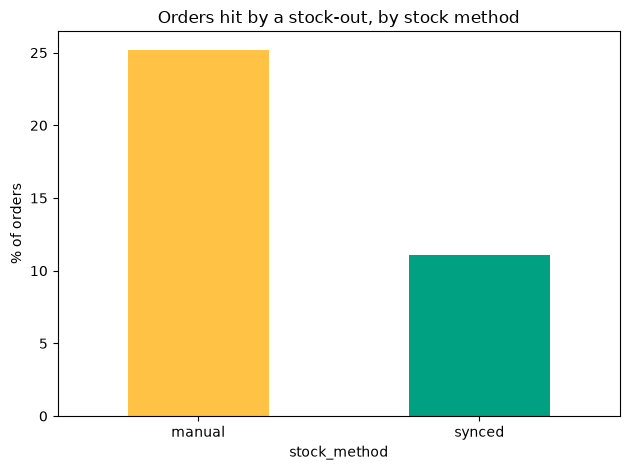

In [4]:
by_method = orders.groupby("stock_method")["any_stockout"].mean() * 100
print("Orders hit by a stock-out, by how the store updates stock (%):")
print(by_method.round(1))

by_method.plot(kind="bar", color=["#FFC244", "#00A082"], title="Orders hit by a stock-out, by stock method")
plt.ylabel("% of orders")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("figures/stockouts_by_method.png", dpi=120)
plt.show()

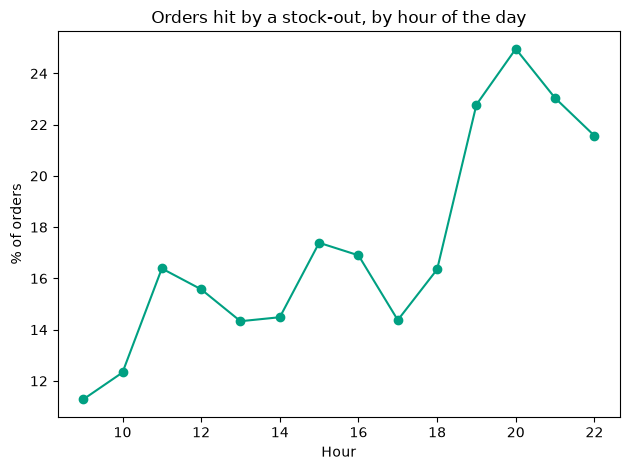

Evening (19:00 or later): 23.4 %
Before 19:00: 15.1 %


In [5]:
by_hour = orders.groupby("hour")["any_stockout"].mean() * 100

by_hour.plot(kind="line", marker="o", color="#00A082", title="Orders hit by a stock-out, by hour of the day")
plt.ylabel("% of orders")
plt.xlabel("Hour")
plt.tight_layout()
plt.savefig("figures/stockouts_by_hour.png", dpi=120)
plt.show()

print("Evening (19:00 or later):", round(orders[orders["hour"] >= 19]["any_stockout"].mean() * 100, 1), "%")
print("Before 19:00:", round(orders[orders["hour"] < 19]["any_stockout"].mean() * 100, 1), "%")

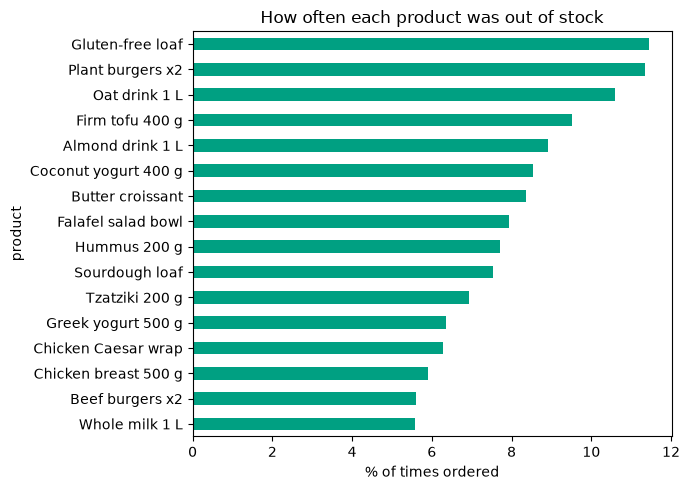

In [6]:
# Which products run out most? (share of times ordered that it was missing)
by_product = lines.groupby("product")["out_of_stock"].apply(lambda x: (x == "yes").mean() * 100)
by_product = by_product.sort_values(ascending=True)

by_product.plot(kind="barh", color="#00A082", title="How often each product was out of stock", figsize=(7, 5))
plt.xlabel("% of times ordered")
plt.tight_layout()
plt.savefig("figures/stockouts_by_product.png", dpi=120)
plt.show()

## 4. What happens after a stock-out?

In [7]:
missing = lines[lines["out_of_stock"] == "yes"]
print("Out-of-stock items:", len(missing))
print()
print((missing["outcome"].value_counts(normalize=True) * 100).round(1))

Out-of-stock items: 1082

outcome
substitute_accepted       65.2
substitute_declined       28.4
refunded_no_substitute     6.5
Name: proportion, dtype: float64


Today the store picks *any* substitute from the same group. Does it fit what the customer wanted (for example vegan for a vegan customer)?

Substitutes that fit the customer's preference: 77.8%

Acceptance rate (%) when the substitute fits / does not fit:
substitute_fits_pref
no     17.3
yes    84.6
Name: outcome, dtype: float64


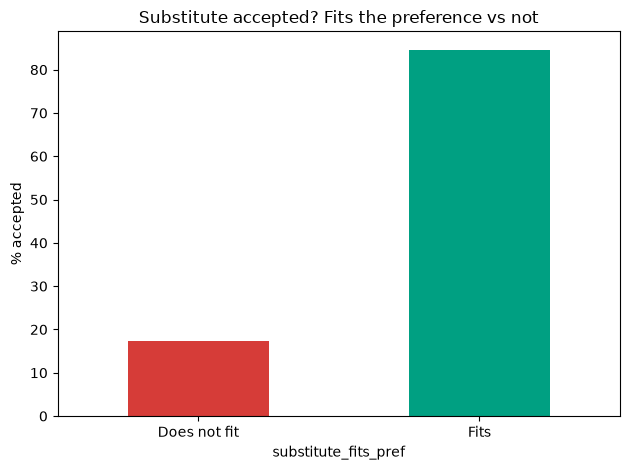

In [8]:
subs = missing[missing["substitute"].notna()]

fit_share = (subs["substitute_fits_pref"] == "yes").mean() * 100
print(f"Substitutes that fit the customer's preference: {fit_share:.1f}%")

acceptance = subs.groupby("substitute_fits_pref")["outcome"].apply(lambda x: (x == "substitute_accepted").mean() * 100)
print()
print("Acceptance rate (%) when the substitute fits / does not fit:")
print(acceptance.round(1))

acceptance.plot(kind="bar", color=["#D63C38", "#00A082"], title="Substitute accepted? Fits the preference vs not")
plt.ylabel("% accepted")
plt.xticks([0, 1], ["Does not fit", "Fits"], rotation=0)
plt.tight_layout()
plt.savefig("figures/acceptance_by_fit.png", dpi=120)
plt.show()

In [9]:
# Same question, only for vegan and gluten-free customers
pref_subs = subs[subs["customer_pref"] != "none"]
print("Vegan and gluten-free customers: substitutes that fit their preference:",
      round((pref_subs["substitute_fits_pref"] == "yes").mean() * 100, 1), "%")

Vegan and gluten-free customers: substitutes that fit their preference: 46.4 %


## 5. What does it cost?

In [10]:
total_refunds = lines["refund_eur"].sum()
total_sales = (lines["price"] * lines["qty"]).sum()
n_orders = len(orders)

print(f"Refunds in 4 weeks: €{total_refunds:,.2f}  ({total_refunds / total_sales * 100:.1f}% of sales)")
print(f"Refunds per 1,000 orders: €{total_refunds / n_orders * 1000:,.0f}")

Refunds in 4 weeks: €1,226.00  (2.7% of sales)
Refunds per 1,000 orders: €226


Average rating (1-5):
had_refund
No refund    4.52
Refund       3.23
Name: rating, dtype: float64

Ordered again within 14 days (%):
had_refund
No refund    87.1
Refund       71.9
Name: ordered_again, dtype: float64


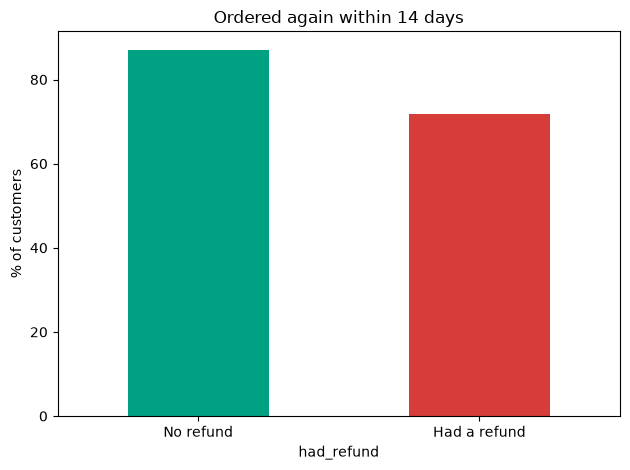

In [11]:
# Ratings: orders with a refund vs without
orders["had_refund"] = orders["refund_eur"] > 0
rated = orders[orders["rating"].notna()]
print("Average rating (1-5):")
print(rated.groupby("had_refund")["rating"].mean().round(2).rename({False: "No refund", True: "Refund"}))

# Repeat orders: did the customer order again within 14 days?
known = orders[orders["ordered_again"].notna()]
repeat = known.groupby("had_refund")["ordered_again"].apply(lambda x: (x == "yes").mean() * 100)
print()
print("Ordered again within 14 days (%):")
print(repeat.round(1).rename({False: "No refund", True: "Refund"}))

repeat.plot(kind="bar", color=["#00A082", "#D63C38"], title="Ordered again within 14 days")
plt.ylabel("% of customers")
plt.xticks([0, 1], ["No refund", "Had a refund"], rotation=0)
plt.tight_layout()
plt.savefig("figures/repeat_by_refund.png", dpi=120)
plt.show()

## 6. Sizing the three fixes (simple what-if estimates)

1. **Live stock sync:** manual stores reach the stock-out rate of synced stores.
2. **Low-stock alerts:** stores act on alerts and prevent a further share of stock-outs (assumed 30%, to be tested).
3. **Intent-aware substitutes:** every substitute fits the customer's preference, so it is accepted at the "fits" rate.

In [12]:
manual_rate = by_method["manual"] / 100
synced_rate = by_method["synced"] / 100
manual_orders = (orders["stock_method"] == "manual").sum()

# Fix 1: fewer stock-outs in manual stores
orders_saved_fix1 = manual_orders * (manual_rate - synced_rate)
refund_per_stockout_order = orders.loc[orders["any_stockout"], "refund_eur"].mean()
print(f"Fix 1: about {orders_saved_fix1:.0f} fewer orders hit by a stock-out in 4 weeks")
print(f"        about €{orders_saved_fix1 * refund_per_stockout_order:,.0f} fewer refunds")

# Fix 2: alerts prevent 30% of the remaining stock-outs (assumption)
remaining = orders["any_stockout"].sum() - orders_saved_fix1
orders_saved_fix2 = remaining * 0.30
print(f"Fix 2: about {orders_saved_fix2:.0f} more orders saved (if 30% of alerts prevent a stock-out)")

# Fix 3: all substitutes fit the preference
accept_fit = acceptance["yes"] / 100
declined_now = (subs["outcome"] == "substitute_declined").sum()
declined_after = len(subs) * (1 - accept_fit)
refund_per_item = subs.loc[subs["outcome"] == "substitute_declined", "refund_eur"].mean()
print(f"Fix 3: declined substitutes drop from {declined_now} to about {declined_after:.0f}")
print(f"        about €{(declined_now - declined_after) * refund_per_item:,.0f} fewer refunds")

Fix 1: about 375 fewer orders hit by a stock-out in 4 weeks
        about €470 fewer refunds
Fix 2: about 181 more orders saved (if 30% of alerts prevent a stock-out)
Fix 3: declined substitutes drop from 307 to about 156
        about €546 fewer refunds


## 7. What this shows (on synthetic data)

- **Stock method matters most:** stores that update stock by hand run out far more often than stores with synced stock, so syncing is the biggest lever.
- **Evenings are the risk window:** stock-outs climb after 19:00, which is when low-stock alerts should be loudest.
- **Substitutes that ignore preferences get refunded:** most refunds come from declined substitutes, and matching the preference lifts acceptance sharply.
- **Refunds cost twice:** customers with a refund rate the order lower and order again less within 14 days.

**Caveats:** the data is synthetic, built with the rules in `data/generate_data.py`, so these results partly reflect those rules. The value is the method: the same steps on real order data would test whether the pattern holds.

**Next steps:** rerun on a real dataset (for example Instacart or Olist from Kaggle), then design an A/B test for each fix with refunds, acceptance rate and ratings as metrics.